In [29]:
from dotenv import load_dotenv, find_dotenv

load_dotenv(find_dotenv(), override=True)

True

In [30]:
!pip install google-genai

In [31]:
from google import genai

In [32]:
import os
client = genai.Client(
    api_key=os.getenv("GEMINI_API_KEY")
)

In [33]:
for model in client.models.list():
    print(model.name)

models/gemini-2.5-flash
models/gemini-2.5-pro
models/gemma-4-26b-a4b-it
models/gemma-4-31b-it
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3.1-flash-lite
models/gemini-3-pro-image
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-nano-banana-2.1
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-4-argon
models/antigravity-preview-05-2026
models/antigravity-preview-09-2026
models/antigravity-preview-latest
models/deep-research-max-preview-04-2026
models/deep-research-preview-04-2026
models/deep-research-pro-preview-12-2025
models/gemini-embedding-001
models/gemini-embedding-2


In [34]:
response = client.models.generate_content(
    model="gemini-3.5-flash-lite",
    contents="Explain Artificial Intelligence in simple words."
)
print(response.text)

Imagine you have a super-smart computer robot friend. 

Usually, computers only do exactly what humans tell them to do, step-by-step. But **Artificial Intelligence (AI)** is different. AI is a way of making computers *think and learn* almost like humans do.

Here is how it works in 3 simple steps:

1. **It learns from examples:** Instead of programming a computer with strict rules, you show it thousands of examples. For example, if you want an AI to recognize cats, you show it 10,000 pictures of cats.
2. **It notices patterns:** The computer looks at all those pictures and figures out the pattern on its own (e.g., "Ah, cats usually have pointy ears, whiskers, and furry tails").
3. **It makes decisions:** Once it learns the pattern, you can show it a brand-new picture, and the computer can say, "That's a cat!" even if it has never seen *that specific* cat before.

### Real-life examples you probably already use:
* **Netflix/YouTube:** They look at what you’ve watched in the past and gue

# Reading the Image

In [35]:
!pip install pillow

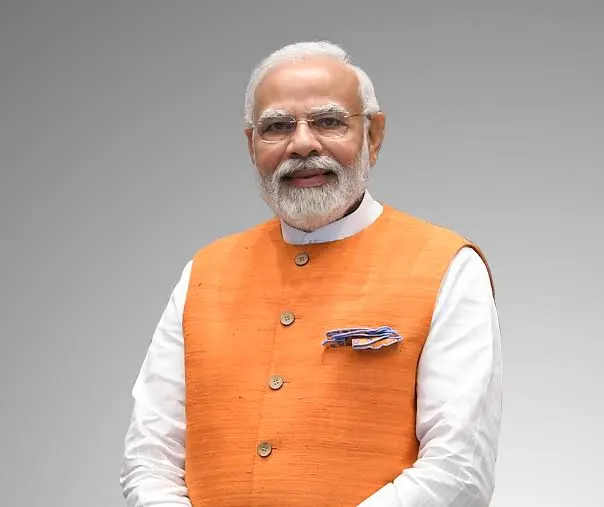

In [36]:
from PIL import Image
img=Image.open('images.webp')
img

In [37]:
text_prompt='Describe thsi image'
response = client.models.generate_content(
    model="gemini-3.5-flash-lite",
    contents=[text_prompt, img])
print(response.text)

A waist up, medium, indoor studio shot shows Narendra Modi, wearing a white long sleeve shirt, an orange colored nehru jacket with a small pocket square on the left, silver framed glasses, and grey hair and beard against a gray gradient background. Narendra Modi is looking at the camera with a slight smile.


# Load Documents

In [38]:
from langchain_community.document_loaders import PyPDFLoader

In [39]:
data=PyPDFLoader('Artificial_Intelligence_10_Page_Document.pdf')
docs=data.load()

Chat Prompt Template

In [40]:
from langchain_core.prompts import ChatPromptTemplate

In [41]:
chat_prompt = ChatPromptTemplate.from_messages([
    ("system", "You are a helpful AI assistant."),
    ("human", "{data}")
])



In [42]:
prompt = chat_prompt.invoke({
    "data":docs[0].page_content
}).to_string()

print(type(prompt))

<class 'str'>


In [43]:
response=client.models.generate_content(
    model='gemini-3.5-flash-lite',
    contents=prompt
)
print(response.text)

It looks like you've shared the title page/cover of a 10-page educational document about Artificial Intelligence! 

How can I help you with this document today? For example, I can:
* Summarize the content if you provide the subsequent pages.
* Answer questions about specific AI topics (history, uses, benefits, risks, or future).
* Create study guides, flashcards, or quizzes based on the text. 

Please go ahead and share the text or let me know what you'd like to do!


# Text-Splitter

In [44]:
pip install -U langchain-text-splitters

Note: you may need to restart the kernel to use updated packages.


In [45]:
from langchain_text_splitters import RecursiveCharacterTextSplitter


In [46]:
text_splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=150)
texts = text_splitter.split_documents(docs)

In [47]:
print(len(texts))

26


In [48]:
print(texts[0].page_content)

Artificial Intelligence | Educational Document
Page 1
 ARTIFICIAL
INTELLIGENCE
 An Introduction to Its History, Uses, Benefits, Risks, and Future
 A 10-Page Educational Document
 Prepared for general educational and study purposes


# Vector Store

In [49]:
!pip install -U langchain-chroma langchain-google-genai

In [50]:
!pip install -U langchain-core langchain-google-genai langchain-chroma langchain-text-splitters langchain-community

In [51]:
import langchain_core
import langchain_google_genai
import langchain_chroma

print("LangChain Core:", langchain_core.__version__)
print("All packages imported successfully!")

LangChain Core: 1.7.6
All packages imported successfully!


In [52]:
from langchain_google_genai import GoogleGenerativeAIEmbeddings
from langchain_chroma import Chroma
from langchain_core.prompts import ChatPromptTemplate

print("Imports Successful!")

Imports Successful!


In [53]:
embeddings = GoogleGenerativeAIEmbeddings(
    model="models/gemini-embedding-001"
)



# Create Chroma Vector dB

In [54]:
vector_store = Chroma(
    collection_name="docs",
    embedding_function=embeddings,
    persist_directory="chroma_langchain_db",
)

In [55]:
vector_store.add_documents(documents=texts)

print("PDF documents added successfully!")

PDF documents added successfully!


# Similarity Search

In [56]:
query = "What is Artificial Intelligence?"

results = vector_store.similarity_search(query, k=3)

for i, doc in enumerate(results):
    print(f"\nDocument {i+1}:")
    print(doc.page_content)


Document 1:
Artificial Intelligence | Educational Document
Page 2
Introduction to Artificial Intelligence
Overview
Artificial Intelligence (AI) is a branch of computer science concerned with creating machines and software that can
perform tasks commonly associated with human intelligence. These tasks include understanding language,
recognizing images, learning from experience, solving problems, making predictions, and supporting decisions. AI
is not a single machine or program. It is a broad collection of methods, technologies, and applications that allow
computer systems to respond intelligently to information.
Why AI Matters
AI has moved from research laboratories into everyday life. It helps people search the internet, receive
recommendations, translate languages, detect suspicious banking activity, navigate roads, and access digital
assistants. Businesses use AI to analyse large amounts of information and improve services. Governments and

Document 2:
others remain fixed until dev

# Create RAG Prompt

In [57]:
from langchain_core.prompts import ChatPromptTemplate

rag_prompt = ChatPromptTemplate.from_template("""
You are a helpful AI assistant.

Answer the question using only the following context.
If the answer is not available in the context, say:
"I could not find this information in the document."

Context:
{context}

Question:
{question}

Answer:
""")

# connect Retrieve with Gemini

In [58]:
query = "What is Artificial Intelligence?"

results = vector_store.similarity_search(query, k=3)

context = "\n\n".join(
    doc.page_content for doc in results
)

prompt = rag_prompt.invoke({
    "context": context,
    "question": query
}).to_string()

response = client.models.generate_content(
    model="gemini-3.5-flash-lite",
    contents=prompt
)

print(response.text)

Based on the provided document, Artificial Intelligence (AI) is a branch of computer science concerned with creating machines and software that can perform tasks commonly associated with human intelligence. These tasks include understanding language, recognizing images, learning from experience, solving problems, making predictions, and supporting decisions.
